In [ ]:
 import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/merge.csv', encoding='latin1')

df.head()

,Title,Author,Year,Citation count,Open access,Corresponding institution,Institution,Institution IDs,Institutions count
0,Tumour-associated macrophages as treatment tar...,Alberto Mantovani|Federica Marchesi|Alberto Ma...,2017,4119,NOT Open Access,https://openalex.org/I1339471597|https://opena...,Humanitas University|Istituti di Ricovero e Cu...,I1339471597|I4210153126|I189158943,3
1,The emerging roles of circRNAs in cancer and o...,Lasse S. Kristensen|Theresa Jakobsen|Henrik Ha...,2021,1397,NOT Open Access,https://openalex.org/I204337017,Aarhus University|Vejle Sygehus,I204337017|I4210091196,2
2,"Colon Cancer, Version 2.2021, NCCN Clinical Pr...",Al B. Benson|Alan P. Venook|Mahmoud M. Al-Hawa...,2021,1772,NOT Open Access,NaN,Robert H. Lurie Comprehensive Cancer Center of...,I4390039227|I4210167126|I27837315|I1301076528|...,44
3,OncoKB: A Precision Oncology Knowledge Base,Debyani Chakravarty|Jianjiong Gao|Sarah Philli...,2017,2739,NOT Open Access,NaN,NaN,NaN,0
4,"Gastric Cancer, Version 2.2022, NCCN Clinical ...",Jaffer A. Ajani|Thomas A. DAmico|David J. Ben...,2022,1745,Open Access,NaN,The University of Texas MD Anderson Cancer Cen...,I1343551460|I2801345345|I4390039326|I439003922...,45


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

In [ ]:
print(df.shape)

In [ ]:
df.head()

In [ ]:
df.info()

In [ ]:
df["Year"].describe()

In [ ]:
df["Year"].value_counts().sort_index()

In [ ]:
df.groupby("Year")["Citation count"].agg(["count", "mean", "median", "sum"])

In [ ]:
df["Open access"].value_counts()

In [ ]:
df.groupby("Open access")["Citation count"].agg(["count", "mean", "median", "std"])

In [ ]:
from scipy.stats import mannwhitneyu

oa = df[df["Open access"] == "Open Access"]["Citation count"]
non_oa = df[df["Open access"] == "NOT Open Access"]["Citation count"]

mannwhitneyu(oa, non_oa, alternative="two-sided")

MannwhitneyuResult(statistic=np.float64(136540049.5), pvalue=np.float64(1.8356024878878336e-16))

In [ ]:
df.groupby("Open access")["Citation count"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

Open access          
NOT Open Access  0.25     15.00
                 0.50     24.00
                 0.75     46.00
                 0.90    104.00
                 0.95    186.00
                 0.99    656.40
Open Access      0.25     16.00
                 0.50     27.00
                 0.75     51.00
                 0.90    104.00
                 0.95    172.00
                 0.99    556.36
Name: Citation count, dtype: float64

In [ ]:
oa_by_year = (
    df.groupby("Year")["Open access"]
      .value_counts(normalize=True)
      .unstack()
      .fillna(0) * 100
)

oa_by_year

Open access,NOT Open Access,Open Access
Year,,
2015,34.191781,65.808219
2016,26.675544,73.324456
2017,28.803157,71.196843
2018,35.324232,64.675768
2019,32.970496,67.029504
2020,26.972073,73.027927
2021,23.227917,76.772083
2022,19.082745,80.917255
2023,17.127072,82.872928


In [ ]:
df.describe(include="all")

,Title,Author,Year,Citation count,Open access,Corresponding institution,Institution,Institution IDs,Institutions count
count,36212,36157,36214.000000,36214.000000,36214,29472,35650,35650,36214.000000
unique,35007,34658,NaN,NaN,2,12590,28885,28916,NaN
top,UpToDate®,Jacopo Giuliani|Andrea Bonetti,NaN,NaN,Open Access,https://openalex.org/I1343551460,The University of Texas MD Anderson Cancer Center,I1343551460,NaN
freq,7,10,NaN,NaN,26433,534,216,216,NaN
mean,NaN,NaN,2019.186309,57.602170,NaN,NaN,NaN,NaN,5.689788
std,NaN,NaN,2.862751,147.868363,NaN,NaN,NaN,NaN,7.397778
min,NaN,NaN,2015.000000,10.000000,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,2017.000000,15.000000,NaN,NaN,NaN,NaN,2.000000
50%,NaN,NaN,2019.000000,26.000000,NaN,NaN,NaN,NaN,3.000000
75%,NaN,NaN,2021.000000,50.000000,NaN,NaN,NaN,NaN,6.000000


In [ ]:
 year_counts = df["Year"].value_counts().sort_index()

year_counts

,count
Year,
2015,3650
2016,4506
2017,4562
2018,3516
2019,3491
2020,4082
2021,3668
2022,3118
2023,2534


In [ ]:
year_counts.plot(kind="line", marker="o", figsize=(10,5))

NameError: name 'year_counts' is not defined

<Axes: xlabel='Open access'>

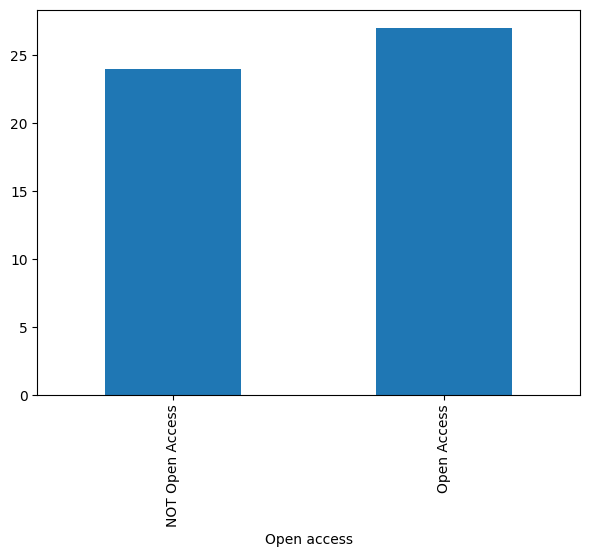

In [ ]:
df.groupby("Open access")["Citation count"].median().plot(
    kind="bar",
    figsize=(7,5)
)

In [ ]:
top10 = df.nlargest(10, "Citation count")[[
    "Title",
    "Author",
    "Year",
    "Citation count",
    "Open access"
]]

top10

,Title,Author,Year,Citation count,Open access
11,The Eighth Edition <scp>AJCC</scp> Cancer Stag...,Mahul B. Amin|Frederick L. Greene|Stephen B. E...,2017,6615,Open Access
30,Pan-cancer Immunogenomic Analyses Reveal Genot...,Pornpimol Charoentong|Francesca Finotello|Miha...,2017,5423,Open Access
111,Atezolizumab versus docetaxel in patients with...,Achim Rittmeyer|Fabrice Barlési|Daniel Waterka...,2016,4801,Open Access
0,Tumour-associated macrophages as treatment tar...,Alberto Mantovani|Federica Marchesi|Alberto Ma...,2017,4119,NOT Open Access
14833,Atezolizumab in patients with locally advanced...,Jonathan E. Rosenberg|Jean Hoffman?Censits|Tom...,2016,3739,NOT Open Access
62,Mutational landscape of metastatic cancer reve...,Ahmet Zehir|Ryma Benayed|Ronak Shah|Aijazuddin...,2017,3563,NOT Open Access
273,Pembrolizumab versus chemotherapy for previous...,Tony Mok|Yi?Long Wu|Iveta Kudaba|Dariusz M. Ko...,2019,3377,Open Access
95,EAU-ESTRO-SIOG Guidelines on Prostate Cancer. ...,Nicolas Mottet|Joaquim Bellmunt|M. Bolla|Erik ...,2016,3268,Open Access
38,CAR T cell immunotherapy for human cancer,Carl H. June|Roddy S. OConnor|Omkar U. Kawale...,2018,3205,NOT Open Access
5593,PROTAC targeted protein degraders: the past is...,Miklós Békés|David R. Langley|Craig M. Crews,2022,3195,Open Access


In [ ]:
cancer_keywords = {
    "Breast cancer": ["breast cancer", "breast carcinoma", "breast tumor"],
    "Lung cancer": ["lung cancer", "lung carcinoma", "lung adenocarcinoma"],
    "Colorectal cancer": ["colorectal cancer", "colon cancer", "rectal cancer"],
    "Prostate cancer": ["prostate cancer", "prostate carcinoma"],
    "Gastric cancer": ["gastric cancer", "stomach cancer"],
    "Liver cancer": ["liver cancer", "hepatocellular carcinoma", "liver carcinoma"],
    "Pancreatic cancer": ["pancreatic cancer", "pancreatic carcinoma"],
    "Ovarian cancer": ["ovarian cancer", "ovarian carcinoma"],
    "Cervical cancer": ["cervical cancer", "cervical carcinoma"],
    "Thyroid cancer": ["thyroid cancer", "thyroid carcinoma"],
    "Kidney cancer": ["kidney cancer", "renal cell carcinoma", "renal cancer"],
    "Bladder cancer": ["bladder cancer", "bladder carcinoma"],
    "Melanoma": ["melanoma"],
    "Leukemia": ["leukemia"],
    "Lymphoma": ["lymphoma"],
    "Brain cancer": ["brain cancer", "brain tumor", "glioma"]
}

In [ ]:
import pandas as pd

title_text = df["Title"].fillna("").str.lower()

cancer_counts = {}

for cancer, keywords in cancer_keywords.items():
    mask = title_text.str.contains("|".join(keywords), regex=True)
    cancer_counts[cancer] = mask.sum()

cancer_counts = (
    pd.Series(cancer_counts)
    .sort_values(ascending=False)
)

cancer_counts

,0
Breast cancer,2945
Lung cancer,2257
Colorectal cancer,1276
Prostate cancer,944
Ovarian cancer,684
Gastric cancer,475
Pancreatic cancer,443
Liver cancer,405
Cervical cancer,379
Melanoma,376


In [ ]:
topic_keywords = {
    "Immunotherapy": ["immunotherapy", "immune checkpoint", "checkpoint inhibitor"],
    "Targeted therapy": ["targeted therapy", "targeted treatment"],
    "Chemotherapy": ["chemotherapy", "chemotherapeutic"],
    "Radiotherapy": ["radiotherapy", "radiation therapy"],
    "Immunology": ["immunology", "immune response", "immune system"],
    "Genomics": ["genomic", "genome", "genomics"],
    "Biomarkers": ["biomarker", "biomarkers"],
    "Genetic mutations": ["mutation", "mutational", "genetic mutation"],
    "Prognosis & survival": ["prognosis", "prognostic", "survival"],
    "Diagnosis": ["diagnosis", "diagnostic"],
    "Screening": ["screening", "early detection"],
    "Prevention": ["prevention", "preventive"],
    "Metastasis": ["metastasis", "metastatic"],
    "Precision medicine": ["precision medicine", "personalized medicine"],
    "Cancer epidemiology": ["epidemiology", "incidence", "mortality"]
}

In [ ]:
topic_counts = {}

for topic, keywords in topic_keywords.items():
    mask = title_text.str.contains("|".join(keywords), regex=True)
    topic_counts[topic] = mask.sum()

topic_counts = (
    pd.Series(topic_counts)
    .sort_values(ascending=False)
)

topic_counts

,0
Prognosis & survival,2429
Metastasis,1955
Chemotherapy,1621
Radiotherapy,1479
Immunotherapy,1463
Diagnosis,956
Biomarkers,798
Genomics,594
Genetic mutations,587
Screening,470


In [ ]:
topic_trends = {}

for topic, keywords in topic_keywords.items():
    mask = title_text.str.contains("|".join(keywords), regex=True)

    topic_trends[topic] = (
        df.loc[mask]
        .groupby("Year")
        .size()
    )

topic_trends = pd.DataFrame(topic_trends).fillna(0)

topic_trends

,Immunotherapy,Targeted therapy,Chemotherapy,Radiotherapy,Immunology,Genomics,Biomarkers,Genetic mutations,Prognosis & survival,Diagnosis,Screening,Prevention,Metastasis,Precision medicine,Cancer epidemiology
Year,,,,,,,,,,,,,,,
2015,44,16,193,175,11.0,50,61,72,281,76,47,30,237,15,38
2016,56,11,233,202,11.0,60,87,104,442,80,54,43,286,33,34
2017,97,21,220,192,12.0,64,103,94,404,90,57,32,263,40,60
2018,113,9,183,161,6.0,62,78,67,238,77,44,25,202,35,36
2019,162,14,168,132,7.0,49,60,45,204,75,49,27,211,37,51
2020,208,12,165,185,12.0,61,88,58,212,76,59,28,180,35,54
2021,188,3,160,143,16.0,72,82,48,214,119,39,19,169,36,55
2022,213,14,112,113,14.0,58,63,47,179,93,37,24,153,30,38
2023,184,16,93,91,7.0,45,70,29,134,97,42,14,127,23,37


In [ ]:
cancer_impact = {}

for cancer, keywords in cancer_keywords.items():
    mask = title_text.str.contains("|".join(keywords), regex=True)

    cancer_impact[cancer] = {
        "Articles": mask.sum(),
        "Median_Citation": df.loc[mask, "Citation count"].median(),
        "Mean_Citation": df.loc[mask, "Citation count"].mean()
    }

cancer_impact = pd.DataFrame(cancer_impact).T.sort_values(
    "Median_Citation", ascending=False
)

cancer_impact

,Articles,Median_Citation,Mean_Citation
Melanoma,376.0,33.0,70.034574
Liver cancer,405.0,32.0,65.409877
Pancreatic cancer,443.0,29.0,53.898420
Prostate cancer,944.0,28.0,72.427966
Thyroid cancer,127.0,28.0,51.133858
Brain cancer,335.0,28.0,51.707463
Ovarian cancer,684.0,27.5,65.834795
Lung cancer,2257.0,27.0,65.339389
Colorectal cancer,1276.0,27.0,60.963166
Kidney cancer,189.0,26.0,51.555556


In [ ]:
cancer_impact.sort_values("Articles", ascending=False)

,Articles,Median_Citation,Mean_Citation
Breast cancer,2945.0,25.0,55.312394
Lung cancer,2257.0,27.0,65.339389
Colorectal cancer,1276.0,27.0,60.963166
Prostate cancer,944.0,28.0,72.427966
Ovarian cancer,684.0,27.5,65.834795
Gastric cancer,475.0,25.0,59.204211
Pancreatic cancer,443.0,29.0,53.898420
Liver cancer,405.0,32.0,65.409877
Cervical cancer,379.0,24.0,53.992084
Melanoma,376.0,33.0,70.034574


In [ ]:
top_cancers = [
    "Breast cancer",
    "Lung cancer",
    "Colorectal cancer",
    "Prostate cancer",
    "Ovarian cancer"
]

cancer_trends = {}

for cancer in top_cancers:
    keywords = cancer_keywords[cancer]
    mask = title_text.str.contains("|".join(keywords), regex=True)

    cancer_trends[cancer] = (
        df.loc[mask]
        .groupby("Year")
        .size()
    )

cancer_trends = pd.DataFrame(cancer_trends).fillna(0)

cancer_trends

,Breast cancer,Lung cancer,Colorectal cancer,Prostate cancer,Ovarian cancer
Year,,,,,
2015,369,233,162,108,70
2016,442,322,217,155,106
2017,393,336,185,125,107
2018,286,229,130,103,80
2019,251,222,99,106,78
2020,287,237,124,80,69
2021,286,196,114,82,50
2022,219,182,83,63,49
2023,188,147,81,58,39


In [ ]:
cancer_summary = cancer_impact.copy()

cancer_summary = cancer_summary.reset_index()
cancer_summary.columns = [
    "Cancer Type",
    "Articles",
    "Median Citation",
    "Mean Citation"
]

cancer_summary

,Cancer Type,Articles,Median Citation,Mean Citation
0,Melanoma,376.0,33.0,70.034574
1,Liver cancer,405.0,32.0,65.409877
2,Pancreatic cancer,443.0,29.0,53.898420
3,Prostate cancer,944.0,28.0,72.427966
4,Thyroid cancer,127.0,28.0,51.133858
5,Brain cancer,335.0,28.0,51.707463
6,Ovarian cancer,684.0,27.5,65.834795
7,Lung cancer,2257.0,27.0,65.339389
8,Colorectal cancer,1276.0,27.0,60.963166
9,Kidney cancer,189.0,26.0,51.555556


In [ ]:
topic_summary = pd.DataFrame({
    "Topic": topic_counts.index,
    "Articles": topic_counts.values
}).reset_index(drop=True)

topic_summary

NameError: name 'topic_counts' is not defined

In [ ]:
dashboard_summary = pd.DataFrame({
    "Metric": [
        "Total Articles",
        "Average Citation",
        "Median Citation",
        "Open Access Articles",
        "Non-Open Access Articles"
    ],
    "Value": [
        len(df),
        df["Citation count"].mean(),
        df["Citation count"].median(),
        (df["Open access"] == "Open Access").sum(),
        (df["Open access"] == "NOT Open Access").sum()
    ]
})

dashboard_summary

NameError: name 'df' is not defined

In [ ]:
cancer_summary.to_csv("cancer_summary.csv", index=False)
topic_summary.to_csv("topic_summary.csv", index=False)
cancer_trends.to_csv("cancer_trends.csv")
dashboard_summary.to_csv("dashboard_summary.csv", index=False)

print("Files saved successfully!")

NameError: name 'cancer_summary' is not defined

In [ ]:
from google.colab import files

files.download("cancer_summary.csv")

FileNotFoundError: Cannot find file: cancer_summary.csv

In [ ]:
from google.colab import files

files.download("topic_summary.csv")
files.download("cancer_trends.csv")
files.download("dashboard_summary.csv")

In [ ]:
import requests

title = df.loc[0, "Title"]

url = "https://api.openalex.org/works"
params = {
    "search": title,
    "per-page": 1
}

response = requests.get(url, params=params)

data = response.json()

data["results"][0]["authorships"]

NameError: name 'df' is not defined

In [ ]:
for i in range(5):
    title = df.loc[i, "Title"]

    response = requests.get(
        "https://api.openalex.org/works",
        params={"search": title, "per-page": 1}
    )

    result = response.json()["results"][0]

    print(i, result["display_name"])
    print(result["authorships"][0]["countries"])
    print()

NameError: name 'df' is not defined

In [ ]:
import requests
import time

country_data = []

for i in range(len(df)):
    title = df.loc[i, "Title"]

    try:
        response = requests.get(
            "https://api.openalex.org/works",
            params={
                "search": title,
                "per-page": 1
            },
            timeout=10
        )

        results = response.json().get("results", [])

        if results:
            result = results[0]

            countries = set()

            for authorship in result.get("authorships", []):
                for country in authorship.get("countries", []):
                    countries.add(country)

            country_data.append(sorted(countries))

        else:
            country_data.append([])

    except:
        country_data.append([])

    if (i + 1) % 500 == 0:
        print(f"{i + 1} articles processed")

df["Countries"] = country_data

print("Done!")

NameError: name 'df' is not defined

In [ ]:
print(df.shape)

NameError: name 'df' is not defined

In [ ]:
import requests

test_results = []

for i in range(100):
    title = df.loc[i, "Title"]

    response = requests.get(
        "https://api.openalex.org/works",
        params={
            "search": title,
            "per-page": 1
        },
        timeout=10
    )

    results = response.json().get("results", [])

    if results:
        countries = set()

        for authorship in results[0].get("authorships", []):
            for country in authorship.get("countries", []):
                countries.add(country)

        test_results.append(sorted(countries))
    else:
        test_results.append([])

print("100 articles processed")
print(test_results[:10])

NameError: name 'df' is not defined

In [ ]:
title = df.loc[0, "Title"]

response = requests.get(
    "https://api.openalex.org/works",
    params={"search": title, "per-page": 1}
)

result = response.json()["results"][0]

print("Title:", result["display_name"])
print("Countries:", [
    country
    for authorship in result.get("authorships", [])
    for country in authorship.get("countries", [])
])

NameError: name 'df' is not defined

In [ ]:
print(response.status_code)
print(response.text[:500])

NameError: name 'response' is not defined

In [ ]:
df["Institution"].head(10)

NameError: name 'df' is not defined

In [ ]:
df[["Institution", "Institution IDs"]].head()

NameError: name 'df' is not defined

In [ ]:
all_institutions = set()

for ids in df["Institution IDs"].dropna():
    for inst_id in ids.split("|"):
        all_institutions.add(inst_id)

print(len(all_institutions))

NameError: name 'df' is not defined

In [ ]:
import requests

inst_id = "I204337017"

url = f"https://api.openalex.org/institutions/{inst_id}"

r = requests.get(url)

print(r.status_code)

data = r.json()

print(data["display_name"])
print(data["country_code"])

200
Aarhus University
DK


In [ ]:
institution_ids = list(all_institutions)

len(institution_ids)

0

In [ ]:
import pandas as pd

institution_country = pd.DataFrame({
    "Institution ID": institution_ids,
    "Country": None
})

institution_country.head()

,Institution ID,Country


In [ ]:
import requests
import time

for i in range(100):
    inst_id = institution_country.loc[i, "Institution ID"]

    try:
        url = f"https://api.openalex.org/institutions/{inst_id}"
        r = requests.get(url, timeout=10)

        if r.status_code == 200:
            data = r.json()
            institution_country.loc[i, "Country"] = data.get("country_code")
        else:
            institution_country.loc[i, "Country"] = "ERROR"

    except:
        institution_country.loc[i, "Country"] = "ERROR"

    if (i + 1) % 20 == 0:
        print(f"{i+1} processed")

print(institution_country.head(20))

In [ ]:
institution_country.to_csv("institution_country_progress.csv", index=False)


In [ ]:
import requests
import time
import pandas as pd

for i in range(len(institution_country)):

    # اگر قبلاً گرفته شده، رد شود
    if pd.notna(institution_country.loc[i, "Country"]):
        continue

    inst_id = institution_country.loc[i, "Institution ID"]

    try:
        url = f"https://api.openalex.org/institutions/{inst_id}"
        r = requests.get(url, timeout=10)

        if r.status_code == 200:
            data = r.json()
            institution_country.loc[i, "Country"] = data.get("country_code")
        else:
            institution_country.loc[i, "Country"] = "ERROR"

    except:
        institution_country.loc[i, "Country"] = "ERROR"

    if (i + 1) % 500 == 0:
        institution_country.to_csv(
            "institution_country_progress.csv",
            index=False
        )
        print(f"{i+1} processed and saved")

print("Finished")

Finished


In [ ]:
institution_country["Country"].value_counts().head(20)

,count
Country,


In [ ]:
# ساخت mapping
country_map = dict(
    zip(
        institution_country["Institution ID"],
        institution_country["Country"]
    )
)

def get_countries(ids):
    if pd.isna(ids):
        return None

    countries = []

    for inst_id in ids.split("|"):
        country = country_map.get(inst_id)

        if pd.notna(country):
            countries.append(country)

    return "|".join(sorted(set(countries)))


df["Countries"] = df["Institution IDs"].apply(get_countries)

In [ ]:
df[["Institution IDs", "Countries"]].head(10)

KeyError: "['Countries'] not in index"

In [ ]:
institution_country["Country"] = institution_country["Country"].replace("ERROR", None)


In [ ]:
country_map = dict(
    zip(
        institution_country["Institution ID"],
        institution_country["Country"]
    )
)

In [ ]:
def get_countries(ids):
    if pd.isna(ids):
        return None

    countries = []

    for inst_id in ids.split("|"):
        country = country_map.get(inst_id)

        if country is not None:
            countries.append(country)

    if countries:
        return "|".join(sorted(set(countries)))
    else:
        return None


df["Countries"] = df["Institution IDs"].apply(get_countries)

In [ ]:
df[["Institution IDs", "Countries"]].head(10)

,Institution IDs,Countries
0,I1339471597|I4210153126|I189158943,None
1,I204337017|I4210091196,None
2,I4390039227|I4210167126|I27837315|I1301076528|...,None
3,NaN,None
4,I1343551460|I2801345345|I4390039326|I439003922...,None
5,|I102322052|I4210150094,None
6,I4390039227|I1326427960|I1332479046|I421008948...,None
7,I2801345345|I32389192|I4210126298|I4390039326|...,None
8,|I4210164401|I2801345345|I4390039326|I42101619...,None
9,|I4210103341|I3019308854|I1299725459|I13132982...,None


In [ ]:
country_articles = (
    df["Countries"]
    .dropna()
    .str.split("|")
    .explode()
    .value_counts()
)

country_articles.head(20)

,count
Countries,


In [ ]:
country_articles["IR"]

KeyError: 'IR'

In [ ]:
top_countries = country_articles.head(10).index.tolist()

top_countries

[]

In [ ]:
country_year = []

for country in top_countries:
    temp = df[df["Countries"].fillna("").str.contains(country)]

    yearly = temp.groupby("Year").size()

    for year, count in yearly.items():
        country_year.append({
            "Country": country,
            "Year": year,
            "Articles": count
        })

country_year = pd.DataFrame(country_year)

country_year.head()

""


In [ ]:
country_year_pivot = country_year.pivot(
    index="Year",
    columns="Country",
    values="Articles"
)

country_year_pivot

KeyError: 'Year'

In [ ]:
country_year_share = country_year_pivot.div(
    country_year_pivot.sum(axis=1),
    axis=0
) * 100

country_year_share.round(1)

Country,AU,BR,CN,DE,FR,MY,PT,TR,TW,US
Year,,,,,,,,,,
2015,1.2,NaN,3.2,4.8,3.6,NaN,0.4,0.4,0.8,85.5
2016,1.6,NaN,8.4,3.5,4.2,NaN,1.0,NaN,1.3,80.1
2017,0.4,0.7,6.4,8.5,3.6,0.4,NaN,0.4,1.1,78.6
2018,3.0,NaN,3.4,7.6,5.9,0.4,NaN,0.4,0.4,78.9
2019,1.6,0.4,3.1,5.5,3.9,0.8,0.4,0.4,NaN,83.9
2020,1.0,1.0,6.2,6.5,5.5,0.7,0.7,0.3,0.7,77.4
2021,1.1,0.4,3.8,8.8,5.4,1.5,0.4,1.1,1.5,75.9
2022,0.4,NaN,5.2,8.6,7.3,1.3,1.3,0.4,0.9,74.6
2023,NaN,1.6,9.8,6.6,2.7,NaN,1.6,0.5,0.5,76.5


In [ ]:
country_citation = (
    df[["Countries", "Citation count"]]
    .dropna()
    .assign(Country=df["Countries"].str.split("|"))
    .explode("Country")
)

country_citation.head()

,Countries,Citation count,Country
0,NaN,NaN,None
1,NaN,NaN,None
2,NaN,NaN,None
3,NaN,NaN,None
4,NaN,NaN,None


In [ ]:
country_impact = country_citation.groupby("Country")["Citation count"].agg(
    Articles="count",
    Total_Citations="sum",
    Mean_Citation="mean",
    Median_Citation="median"
).sort_values(
    "Mean_Citation",
    ascending=False
)

country_impact.head(20)

,Articles,Total_Citations,Mean_Citation,Median_Citation
Country,,,,


In [ ]:
country_impact_filtered = country_impact[
    country_impact["Articles"] >= 100
].sort_values(
    "Mean_Citation",
    ascending=False
)

country_impact_filtered.head(20)

,Articles,Total_Citations,Mean_Citation,Median_Citation
Country,,,,
FR,119,13711,115.218487,46.0
US,1981,219352,110.727915,37.0
DE,172,15760,91.627907,33.0
CN,153,8885,58.071895,30.0


In [ ]:
df.columns

In [ ]:
cancer_keywords = [
    "Breast cancer",
    "Lung cancer",
    "Colorectal cancer",
    "Prostate cancer",
    "Ovarian cancer",
    "Gastric cancer",
    "Pancreatic cancer",
    "Liver cancer",
    "Melanoma",
    "Cervical cancer",
    "Leukemia",
    "Lymphoma",
    "Brain cancer",
    "Bladder cancer",
    "Kidney cancer",
    "Thyroid cancer"
]


def find_cancers(title):
    if pd.isna(title):
        return None

    found = []
    title_lower = title.lower()

    for cancer in cancer_keywords:
        if cancer.lower() in title_lower:
            found.append(cancer)

    return "|".join(found) if found else None


df["Cancer Type"] = df["Title"].apply(find_cancers)

In [ ]:
df["Cancer Type"].notna().sum()

np.int64(10225)

In [ ]:
country_cancer = (
    df[["Countries", "Cancer Type"]]
    .dropna()
    .assign(
        Country=df["Countries"].str.split("|"),
        Cancer=df["Cancer Type"].str.split("|")
    )
    .explode("Country")
    .explode("Cancer")
)


top_cancers_by_country = (
    country_cancer
    .groupby(["Country","Cancer"])
    .size()
    .reset_index(name="Articles")
    .sort_values(
        ["Country","Articles"],
        ascending=[True,False]
    )
)

In [ ]:
df.head()

,Title,Author,Year,Citation count,Open access,Corresponding institution,Institution,Institution IDs,Institutions count,Countries,Cancer Type
0,Tumour-associated macrophages as treatment tar...,Alberto Mantovani|Federica Marchesi|Alberto Ma...,2017,4119,NOT Open Access,https://openalex.org/I1339471597|https://opena...,Humanitas University|Istituti di Ricovero e Cu...,I1339471597|I4210153126|I189158943,3,None,None
1,The emerging roles of circRNAs in cancer and o...,Lasse S. Kristensen|Theresa Jakobsen|Henrik Ha...,2021,1397,NOT Open Access,https://openalex.org/I204337017,Aarhus University|Vejle Sygehus,I204337017|I4210091196,2,None,None
2,"Colon Cancer, Version 2.2021, NCCN Clinical Pr...",Al B. Benson|Alan P. Venook|Mahmoud M. Al-Hawa...,2021,1772,NOT Open Access,NaN,Robert H. Lurie Comprehensive Cancer Center of...,I4390039227|I4210167126|I27837315|I1301076528|...,44,None,None
3,OncoKB: A Precision Oncology Knowledge Base,Debyani Chakravarty|Jianjiong Gao|Sarah Philli...,2017,2739,NOT Open Access,NaN,NaN,NaN,0,None,None
4,"Gastric Cancer, Version 2.2022, NCCN Clinical ...",Jaffer A. Ajani|Thomas A. DAmico|David J. Ben...,2022,1745,Open Access,NaN,The University of Texas MD Anderson Cancer Cen...,I1343551460|I2801345345|I4390039326|I439003922...,45,None,Gastric cancer


In [ ]:
[c for c in globals().keys() if "country" in c.lower()]

['country_data',
 'institution_country',
 'country_map',
 'country_articles',
 'country_year',
 'country_citation',
 'country_impact',
 'country_cancer',
 'top_cancers_by_country']

In [ ]:
os.listdir()

NameError: name 'os' is not defined

In [ ]:
top10_articles = (
    df.sort_values(
        "Citation count",
        ascending=False
    )
    .head(10)
)

top10_articles[
    [
        "Title",
        "Year",
        "Citation count",
        "Countries",
        "Institution"
    ]
]

,Title,Year,Citation count,Countries,Institution
11,The Eighth Edition <scp>AJCC</scp> Cancer Stag...,2017,6615,None,University of Tennessee Health Science Center|...
30,Pan-cancer Immunogenomic Analyses Reveal Genot...,2017,5423,None,Innsbruck Medical University|Universität Innsb...
111,Atezolizumab versus docetaxel in patients with...,2016,4801,None,|Aix-Marseille Université|Assistance Publique ...
0,Tumour-associated macrophages as treatment tar...,2017,4119,None,Humanitas University|Istituti di Ricovero e Cu...
14833,Atezolizumab in patients with locally advanced...,2016,3739,None,Memorial Sloan Kettering Cancer Center|Thomas ...
62,Mutational landscape of metastatic cancer reve...,2017,3563,None,Memorial Sloan Kettering Cancer Center|Molecul...
273,Pembrolizumab versus chemotherapy for previous...,2019,3377,None,Chinese University of Hong Kong|Guangdong Gene...
95,EAU-ESTRO-SIOG Guidelines on Prostate Cancer. ...,2016,3268,None,Centre Hospitalier Universitaire de Saint-Étie...
38,CAR T cell immunotherapy for human cancer,2018,3205,None,Parker Institute for Cancer Immunotherapy|Univ...
5593,PROTAC targeted protein degraders: the past is...,2022,3195,None,Arvinas (United States)|Yale University


In [ ]:
top10_articles = top10_articles.reset_index(drop=True)

top10_articles.insert(
    0,
    "Rank",
    range(1,11)
)

top10_articles

,Rank,Title,Author,Year,Citation count,Open access,Corresponding institution,Institution,Institution IDs,Institutions count,Countries,Cancer Type
0,1,The Eighth Edition <scp>AJCC</scp> Cancer Stag...,Mahul B. Amin|Frederick L. Greene|Stephen B. E...,2017,6615,Open Access,https://openalex.org/I160606119,University of Tennessee Health Science Center|...,I160606119|I4210100342|I1292894508|I4210125099...,9,None,None
1,2,Pan-cancer Immunogenomic Analyses Reveal Genot...,Pornpimol Charoentong|Francesca Finotello|Miha...,2017,5423,Open Access,https://openalex.org/I143397708|https://openal...,Innsbruck Medical University|Universität Innsb...,I143397708|I190249584,2,None,None
2,3,Atezolizumab versus docetaxel in patients with...,Achim Rittmeyer|Fabrice Barlési|Daniel Waterka...,2016,4801,Open Access,https://openalex.org/I4390039352|https://opena...,|Aix-Marseille Université|Assistance Publique ...,|I21491767|I4210087487|I2802194831|I848706|I71...,22,None,Lung cancer
3,4,Tumour-associated macrophages as treatment tar...,Alberto Mantovani|Federica Marchesi|Alberto Ma...,2017,4119,NOT Open Access,https://openalex.org/I1339471597|https://opena...,Humanitas University|Istituti di Ricovero e Cu...,I1339471597|I4210153126|I189158943,3,None,None
4,5,Atezolizumab in patients with locally advanced...,Jonathan E. Rosenberg|Jean Hoffman?Censits|Tom...,2016,3739,NOT Open Access,https://openalex.org/I1334819555,Memorial Sloan Kettering Cancer Center|Thomas ...,I1334819555|I149251103|I4210106595|I166337079|...,36,None,None
5,6,Mutational landscape of metastatic cancer reve...,Ahmet Zehir|Ryma Benayed|Ronak Shah|Aijazuddin...,2017,3563,NOT Open Access,https://openalex.org/I1334819555|https://opena...,Memorial Sloan Kettering Cancer Center|Molecul...,I1334819555|I4210150208,2,None,None
6,7,Pembrolizumab versus chemotherapy for previous...,Tony Mok|Yi?Long Wu|Iveta Kudaba|Dariusz M. Ko...,2019,3377,Open Access,https://openalex.org/I177725633,Chinese University of Hong Kong|Guangdong Gene...,I177725633|I2799425052|I4210145693|I4210097420...,16,None,Lung cancer
7,8,EAU-ESTRO-SIOG Guidelines on Prostate Cancer. ...,Nicolas Mottet|Joaquim Bellmunt|M. Bolla|Erik ...,2016,3268,Open Access,https://openalex.org/I4210157006,Centre Hospitalier Universitaire de Saint-Étie...,I4210157006|I136199984|I4210117453|I2800555055...,27,None,Prostate cancer
8,9,CAR T cell immunotherapy for human cancer,Carl H. June|Roddy S. OConnor|Omkar U. Kawale...,2018,3205,NOT Open Access,https://openalex.org/I4210109986|https://opena...,Parker Institute for Cancer Immunotherapy|Univ...,I4210109986|I79576946|,2,None,None
9,10,PROTAC targeted protein degraders: the past is...,Miklós Békés|David R. Langley|Craig M. Crews,2022,3195,Open Access,https://openalex.org/I32971472|https://openale...,Arvinas (United States)|Yale University,I4210142342|I32971472,2,None,None


In [ ]:
top10_articles[
    [
        "Rank",
        "Title",
        "Year",
        "Citation count",
        "Countries",
        "Institutions count"
    ]
]

,Rank,Title,Year,Citation count,Countries,Institutions count
0,1,The Eighth Edition <scp>AJCC</scp> Cancer Stag...,2017,6615,None,9
1,2,Pan-cancer Immunogenomic Analyses Reveal Genot...,2017,5423,None,2
2,3,Atezolizumab versus docetaxel in patients with...,2016,4801,None,22
3,4,Tumour-associated macrophages as treatment tar...,2017,4119,None,3
4,5,Atezolizumab in patients with locally advanced...,2016,3739,None,36
5,6,Mutational landscape of metastatic cancer reve...,2017,3563,None,2
6,7,Pembrolizumab versus chemotherapy for previous...,2019,3377,None,16
7,8,EAU-ESTRO-SIOG Guidelines on Prostate Cancer. ...,2016,3268,None,27
8,9,CAR T cell immunotherapy for human cancer,2018,3205,None,2
9,10,PROTAC targeted protein degraders: the past is...,2022,3195,None,2


In [ ]:
top10_articles["Year"].value_counts()

,count
Year,
2017,4
2016,3
2019,1
2018,1
2022,1


In [ ]:
top10_articles["Citation count"].sum()

np.int64(41305)

In [ ]:
top10_articles["Citation count"].mean()


np.float64(4130.5)

In [ ]:
top10_articles["Open access"].value_counts()

,count
Open access,
Open Access,6
NOT Open Access,4


In [ ]:
top10_articles["Year"].value_counts().sort_index()

,count
Year,
2016,3
2017,4
2018,1
2019,1
2022,1


In [ ]:
df["Country_count"] = (
    df["Countries"]
    .fillna("")
    .apply(lambda x: 0 if x=="" else len(x.split("|")))
)

df["Country_count"].value_counts().sort_index()

,count
Country_count,
0,36214


In [ ]:
collaboration_summary = pd.DataFrame({
    "Type": [
        "Single-country publications",
        "International collaborations"
    ],
    "Articles": [
        (df["Country_count"] == 1).sum(),
        (df["Country_count"] > 1).sum()
    ]
})

collaboration_summary

,Type,Articles
0,Single-country publications,0
1,International collaborations,0


In [ ]:
df["Country_count"].mean()

np.float64(0.0)

In [ ]:
country_pairs = (
    df["Countries"]
    .dropna()
    .str.split("|")
)


pairs = []

for countries in country_pairs:
    countries = sorted(set(countries))

    if len(countries) > 1:
        for i in range(len(countries)):
            for j in range(i+1, len(countries)):
                pairs.append(
                    (countries[i], countries[j])
                )


pair_df = pd.DataFrame(
    pairs,
    columns=["Country1","Country2"]
)


pair_summary = (
    pair_df
    .value_counts()
    .reset_index(name="Articles")
)

pair_summary.head(20)

,Country1,Country2,Articles


In [ ]:
country_collab = (
    df["Countries"]
    .dropna()
    .str.split("|")
    .explode()
    .value_counts()
)

country_collab.head(20)

NameError: name 'df' is not defined

In [ ]:
df.columns

NameError: name 'df' is not defined

In [ ]:
df["Countries"].notna().sum()

np.int64(0)

In [ ]:
df[["Institution IDs","Countries"]].head(10)

,Institution IDs,Countries
0,I1339471597|I4210153126|I189158943,None
1,I204337017|I4210091196,None
2,I4390039227|I4210167126|I27837315|I1301076528|...,None
3,NaN,None
4,I1343551460|I2801345345|I4390039326|I439003922...,None
5,|I102322052|I4210150094,None
6,I4390039227|I1326427960|I1332479046|I421008948...,None
7,I2801345345|I32389192|I4210126298|I4390039326|...,None
8,|I4210164401|I2801345345|I4390039326|I42101619...,None
9,|I4210103341|I3019308854|I1299725459|I13132982...,None


In [ ]:
all_ids = (
    df["Institution IDs"]
    .dropna()
    .str.split("|")
    .explode()
    .str.strip()
)

all_ids = all_ids[all_ids != ""]

unique_ids = all_ids.unique()

len(unique_ids)

16552

In [ ]:
institution_country_map = {}

In [ ]:
test_ids = unique_ids[:20]

for inst_id in test_ids:
    url = f"https://api.openalex.org/institutions/{inst_id}"
    r = requests.get(url)
    print(inst_id, r.status_code)

NameError: name 'unique_ids' is not defined

In [ ]:
import requests
import time
import pickle

institution_country_map = {}

for i, inst_id in enumerate(unique_ids):

    url = f"https://api.openalex.org/institutions/{inst_id}"

    try:
        r = requests.get(url, timeout=10)

        if r.status_code == 200:
            data = r.json()
            institution_country_map[inst_id] = data.get("country_code")

        else:
            institution_country_map[inst_id] = None

    except:
        institution_country_map[inst_id] = None

    if (i+1) % 500 == 0:
        print(i+1, "processed and saved")

        with open("institution_country_map.pkl", "wb") as f:
            pickle.dump(institution_country_map, f)

        time.sleep(2)

In [ ]:
df["Institutions count"].describe()

,Institutions count
count,36214.000000
mean,5.689788
std,7.397778
min,0.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,331.000000


In [ ]:
len(institution_country_map)

0

In [ ]:
def get_countries(ids):
    if pd.isna(ids):
        return None

    countries = []

    for inst_id in ids.split("|"):
        inst_id = inst_id.strip()

        if inst_id in institution_country_map:
            c = institution_country_map[inst_id]
            if c:
                countries.append(c)

    return "|".join(sorted(set(countries))) if countries else None


df["Countries"] = df["Institution IDs"].apply(get_countries)

In [ ]:
df["Countries"].notna().sum()

np.int64(0)

In [ ]:
df["Institutions count"].describe()

,Institutions count
count,36214.000000
mean,5.689788
std,7.397778
min,0.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,331.000000


In [ ]:
df["Institutions count"].value_counts().head(15)

,count
Institutions count,
2,6688
3,5664
1,5342
4,4057
5,3076
6,2105
7,1565
8,1144
9,890


In [ ]:
df.sort_values(
    "Institutions count",
    ascending=False
)[
    ["Title","Year","Institutions count","Citation count"]
].head(10)

,Title,Year,Institutions count,Citation count
213,The tale of TILs in breast cancer: A report fr...,2021,331,282
1516,Report on computational assessment of Tumor In...,2020,197,168
5875,Image?based multiplex immune profiling of canc...,2024,161,16
1952,Pitfalls in machine learning?based assessment ...,2023,159,53
2044,Spatial analyses of immune cell infiltration i...,2023,158,51
5630,EAUESMO consensus statements on the managemen...,2019,149,183
1264,Designing a broad-spectrum integrative approac...,2015,143,302
34876,Predictors of anastomotic leak and conduit nec...,2024,138,13
3438,EAU-ESMO Consensus Statements on the Managemen...,2019,137,194
1095,ESMO / ASCO Recommendations for a Global Curri...,2016,118,131


In [ ]:
df["Institutions count"].describe()

,Institutions count
count,36214.000000
mean,5.689788
std,7.397778
min,0.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,331.000000


In [ ]:
df["Institutions count"].value_counts().sort_index().head(15)

,count
Institutions count,
0,429
1,5342
2,6688
3,5664
4,4057
5,3076
6,2105
7,1565
8,1144


In [ ]:
collab_by_year = (
    df.groupby("Year")
    .agg(
        Publications=("Title", "count"),
        Avg_Institutions=("Institutions count", "mean")
    )
    .reset_index()
)

collab_by_year

,Year,Publications,Avg_Institutions
0,2015,3650,4.645479
1,2016,4506,4.944962
2,2017,4562,4.824858
3,2018,3516,5.019625
4,2019,3491,5.705242
5,2020,4082,6.163645
6,2021,3668,6.226554
7,2022,3116,6.268121
8,2023,2534,6.935675
9,2024,1925,7.487792


In [ ]:
# Dashboard-ready datasets

year_trend = (
    df.groupby("Year")
    .agg(
        Publications=("Title", "count"),
        Avg_Citations=("Citation count", "mean"),
        Avg_Institutions=("Institutions count", "mean")
    )
    .reset_index()
)

oa_summary = (
    df.groupby("Open access")
    .agg(
        Publications=("Title", "count"),
        Avg_Citations=("Citation count", "mean")
    )
    .reset_index()
)

institution_summary = (
    df.groupby("Year")
    .agg(
        Publications=("Title", "count"),
        Avg_Institutions=("Institutions count", "mean")
    )
    .reset_index()
)

year_trend.to_csv("01_publication_trend.csv", index=False)
oa_summary.to_csv("02_open_access_summary.csv", index=False)
institution_summary.to_csv("04_institutional_collaboration.csv", index=False)

print("Done — 3 dashboard-ready CSV files created.")

Done — 3 dashboard-ready CSV files created.


In [ ]:
# Final master dataset for Tableau / Power BI

tableau_df = df.copy()

# Clean column names
tableau_df.columns = (
    tableau_df.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Make sure numeric fields are numeric
tableau_df["Year"] = pd.to_numeric(tableau_df["Year"], errors="coerce")
tableau_df["Citation_count"] = pd.to_numeric(
    tableau_df["Citation_count"], errors="coerce"
)
tableau_df["Institutions_count"] = pd.to_numeric(
    tableau_df["Institutions_count"], errors="coerce"
)

# Keep only the analysis period
tableau_df = tableau_df[
    tableau_df["Year"].between(2015, 2025)
].copy()

# Save master file
tableau_df.to_csv(
    "Oncology_OpenAlex_Master_Dashboard.csv",
    index=False
)

print("Master dashboard file created.")
print("Rows:", len(tableau_df))
print("Columns:", len(tableau_df.columns))
print(tableau_df.columns.tolist())

Master dashboard file created.
Rows: 36214
Columns: 10
['Title', 'Author', 'Year', 'Citation_count', 'Open_access', 'Corresponding_institution', 'Institution', 'Institution_IDs', 'Institutions_count', 'Countries']
